<a href="https://colab.research.google.com/github/Ahadsportfolio/Computer-Graphics-and-Image-Processing-Lab-CSE418-/blob/main/Lab03_Intensity_Transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Report 03 - Intensity Transformation
**Course:** Graphics Design and Digital Image Processing

**University:** University of Science and Technology Chittagong (USTC)

**Name:** Ataullah Ahad | ID: 23070161

Tasks covered:
1. Histogram equalization and the histogram equalizer
2. AND, OR, NOT operations
3. Four arithmetic operations
4. Spatial masks: Sobel, Box, Weighted average, Gaussian, Sharpening, Min/Max/Mean/Median
5. Laplacian, Enhanced Laplacian, High-boost

## 0. Setup

In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage import data

os.makedirs('outputs', exist_ok=True)

def show(imgs, titles, cols=3, size=4, save=None):
    """Display images in a grid (grayscale, fixed 0-255 range) and optionally save the figure."""
    rows = int(np.ceil(len(imgs) / cols))
    plt.figure(figsize=(size * cols, size * rows))
    for i, (im, t) in enumerate(zip(imgs, titles)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(im, cmap='gray', vmin=0, vmax=255)
        plt.title(t, fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    if save:
        plt.savefig(f'outputs/{save}.png', dpi=150, bbox_inches='tight')
    plt.show()

def to_u8(x):
    """Clip to 0-255 and convert to uint8."""
    return np.clip(x, 0, 255).astype(np.uint8)

def norm_u8(x):
    """Min-max scale any array to 0-255 uint8 (for display of Laplacian/gradient results)."""
    x = x.astype(np.float64)
    return to_u8(255 * (x - x.min()) / (x.max() - x.min() + 1e-9))

## 1. Load the input image
By default a sample image is used so the notebook always runs. To use **your own image**, set `USE_UPLOAD = True` and upload it when prompted.

Input image shape: (512, 512) | dtype: uint8


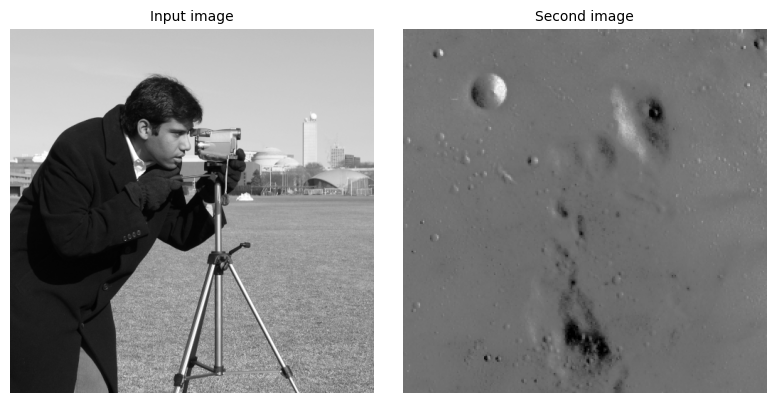

In [2]:
USE_UPLOAD = False   # set True to upload your own image

if USE_UPLOAD:
    from google.colab import files
    up = files.upload()
    name = list(up.keys())[0]
    img = cv2.imread(name, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (512, 512))
else:
    img = data.camera()                     # 512x512 grayscale sample

# Second image (used for AND/OR and arithmetic operations)
try:
    img2 = cv2.resize(data.moon(), (512, 512))
except Exception:
    img2 = np.tile(np.linspace(0, 255, 512).astype(np.uint8), (512, 1))   # fallback: gradient

print('Input image shape:', img.shape, '| dtype:', img.dtype)
show([img, img2], ['Input image', 'Second image'], cols=2, save='00_inputs')

## Task 1: Histogram Equalization and Histogram Equalizer

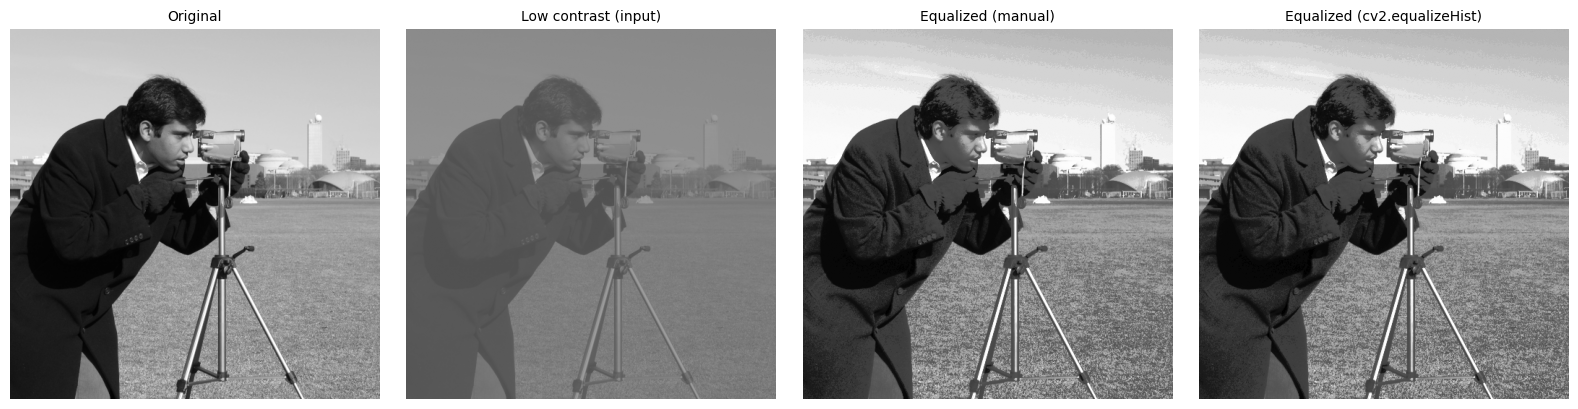

/tmp/ipykernel_561/2180105768.py:21: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  ax[0].hist(low.ravel(), 256, [0, 256], color='gray');      ax[0].set_title('Histogram: low-contrast input')
/tmp/ipykernel_561/2180105768.py:22: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  ax[1].hist(eq_manual.ravel(), 256, [0, 256], color='gray'); ax[1].set_title('Histogram: after equalization')


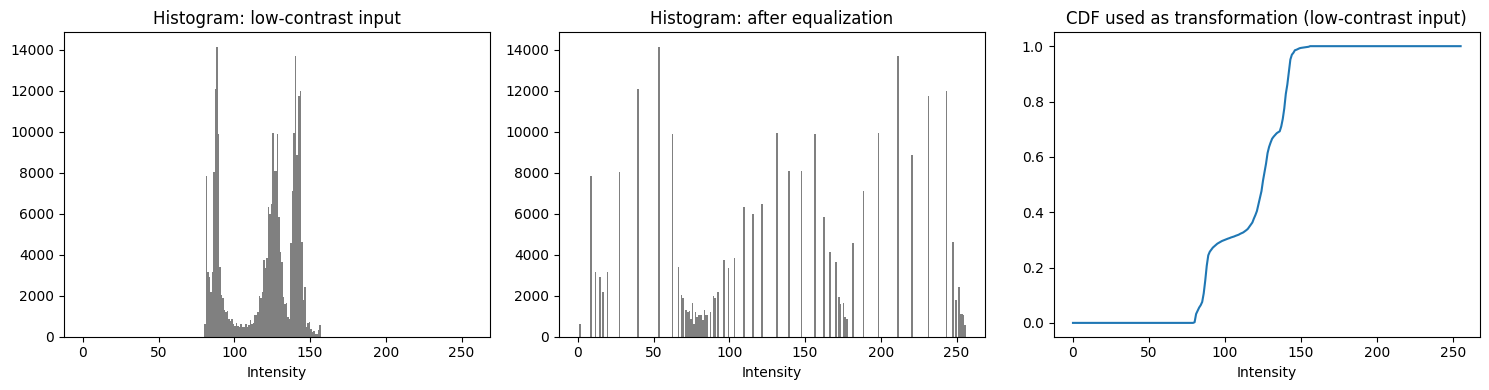

Max abs difference manual vs OpenCV: 1


In [3]:
def my_hist_eq(image):
    """Histogram equalizer from scratch: histogram -> PDF -> CDF -> LUT."""
    hist = np.bincount(image.ravel(), minlength=256)
    pdf = hist / image.size
    cdf = np.cumsum(pdf)
    lut = np.round(255 * cdf).astype(np.uint8)   # s_k = (L-1) * CDF(r_k)
    return lut[image], hist, cdf

# Make a low-contrast version so the effect is obvious
low = to_u8(img * 0.3 + 80)

eq_manual, hist_low, cdf_low = my_hist_eq(low)
eq_cv = cv2.equalizeHist(low)                     # OpenCV built-in for comparison

show([img, low, eq_manual, eq_cv],
     ['Original', 'Low contrast (input)', 'Equalized (manual)', 'Equalized (cv2.equalizeHist)'],
     cols=4, save='01_hist_eq_images')

# Histograms + CDF
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(low.ravel(), 256, [0, 256], color='gray');      ax[0].set_title('Histogram: low-contrast input')
ax[1].hist(eq_manual.ravel(), 256, [0, 256], color='gray'); ax[1].set_title('Histogram: after equalization')
ax[2].plot(cdf_low, color='tab:blue');                      ax[2].set_title('CDF used as transformation (low-contrast input)')
for a in ax: a.set_xlabel('Intensity')
plt.tight_layout(); plt.savefig('outputs/01_hist_eq_histograms.png', dpi=150); plt.show()

print('Max abs difference manual vs OpenCV:', int(np.abs(eq_manual.astype(int) - eq_cv.astype(int)).max()))

## Task 2: AND, OR and NOT operations

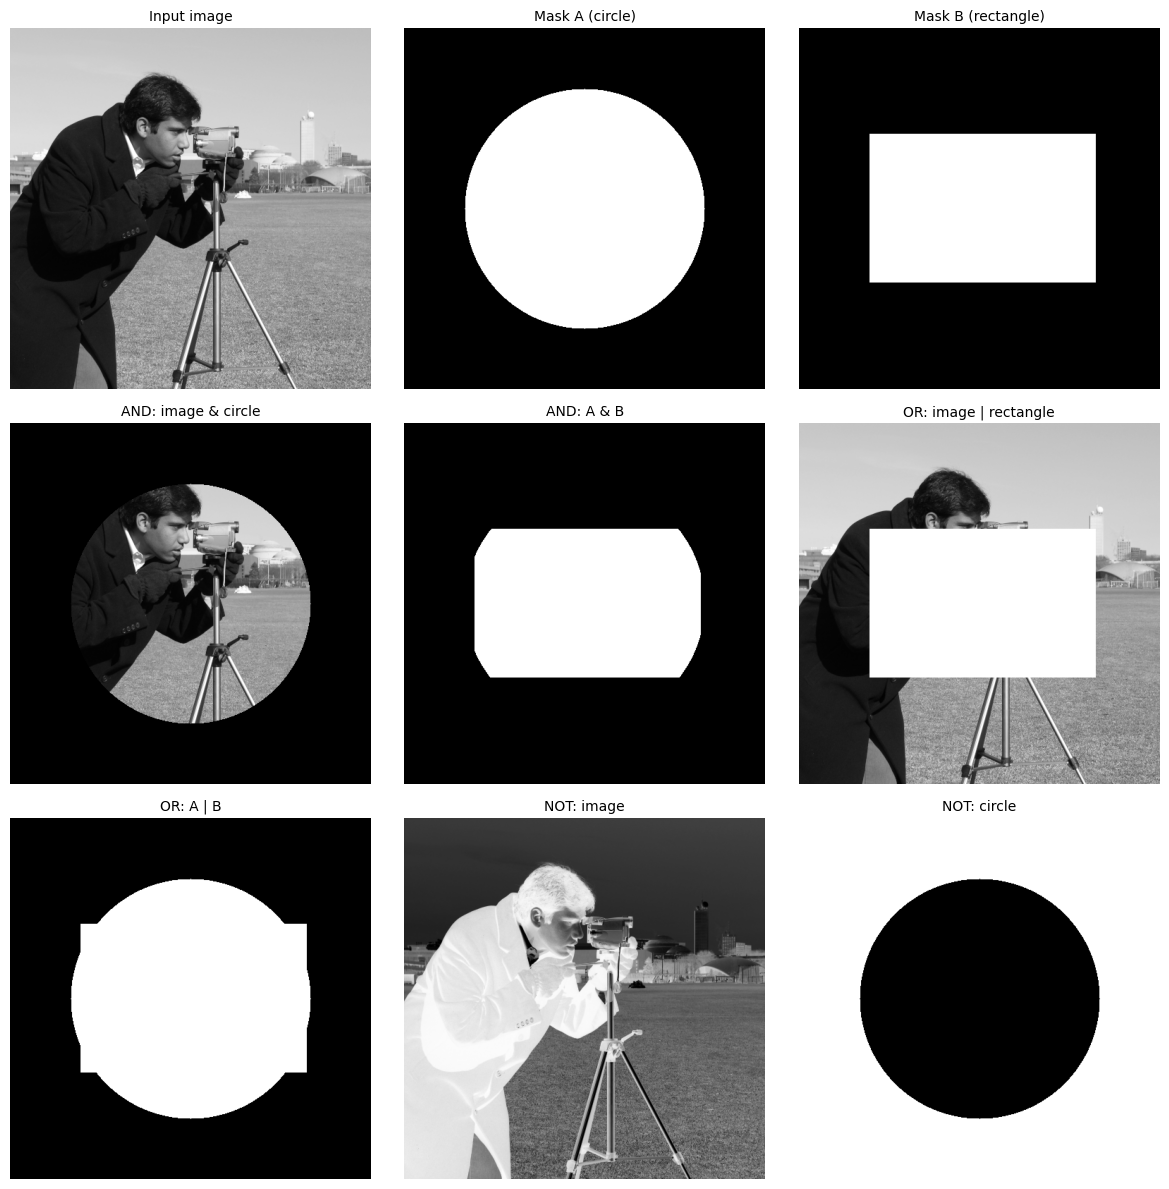

In [4]:
# Binary mask (white circle) and a rectangle image for logical operations
mask_circle = np.zeros_like(img)
cv2.circle(mask_circle, (256, 256), 170, 255, -1)

mask_rect = np.zeros_like(img)
cv2.rectangle(mask_rect, (100, 150), (420, 360), 255, -1)

and_img  = cv2.bitwise_and(img, img, mask=mask_circle)   # keeps image inside the circle
and_two  = cv2.bitwise_and(mask_circle, mask_rect)       # AND of two masks
or_img   = cv2.bitwise_or(img, mask_rect)                # OR image with rectangle
or_two   = cv2.bitwise_or(mask_circle, mask_rect)
not_img  = cv2.bitwise_not(img)                          # negative image: 255 - r
not_mask = cv2.bitwise_not(mask_circle)

show([img, mask_circle, mask_rect, and_img, and_two, or_img, or_two, not_img, not_mask],
     ['Input image', 'Mask A (circle)', 'Mask B (rectangle)',
      'AND: image & circle', 'AND: A & B', 'OR: image | rectangle',
      'OR: A | B', 'NOT: image', 'NOT: circle'],
     cols=3, save='02_logical_ops')

## Task 3: Four arithmetic operations

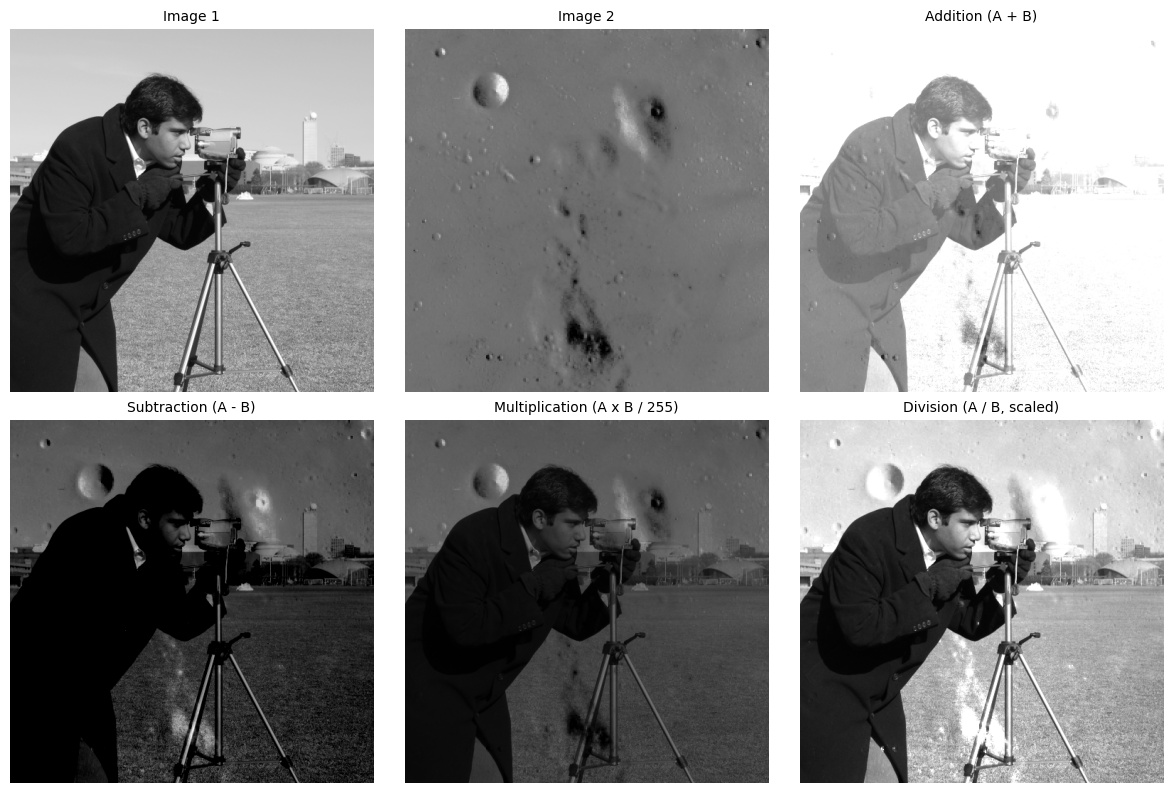

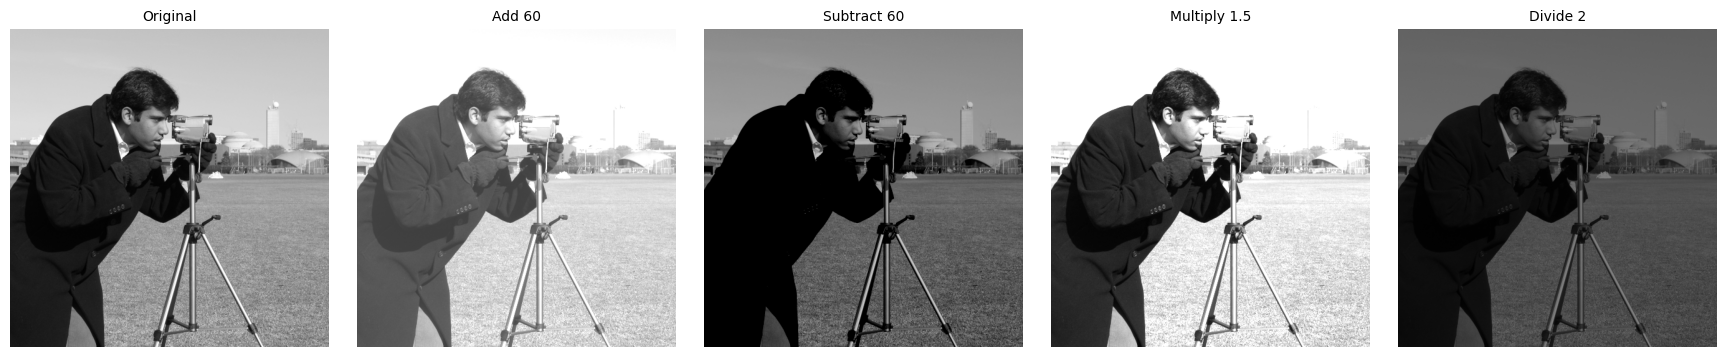

In [5]:
a = img.astype(np.float64)
b = img2.astype(np.float64)

# Image (op) Image
add_img = to_u8(a + b)
sub_img = to_u8(a - b)
mul_img = to_u8(a * b / 255.0)               # scaled so the result stays in range
div_img = to_u8(a / (b + 1.0) * 128.0)       # +1 avoids divide-by-zero, x128 for visibility

show([img, img2, add_img, sub_img, mul_img, div_img],
     ['Image 1', 'Image 2', 'Addition (A + B)', 'Subtraction (A - B)',
      'Multiplication (A x B / 255)', 'Division (A / B, scaled)'],
     cols=3, save='03_arithmetic_image_image')

# Image (op) Constant
add_c = cv2.add(img, 60)                     # brighter
sub_c = cv2.subtract(img, 60)                # darker
mul_c = to_u8(a * 1.5)                       # contrast up
div_c = to_u8(a / 2.0)                       # contrast down

show([img, add_c, sub_c, mul_c, div_c],
     ['Original', 'Add 60', 'Subtract 60', 'Multiply 1.5', 'Divide 2'],
     cols=5, size=3.5, save='03_arithmetic_constant')

## Task 4: Spatial masks (filters)
Each mask is shown with its kernel, the input, and the output.

### 4a. Sobel operator

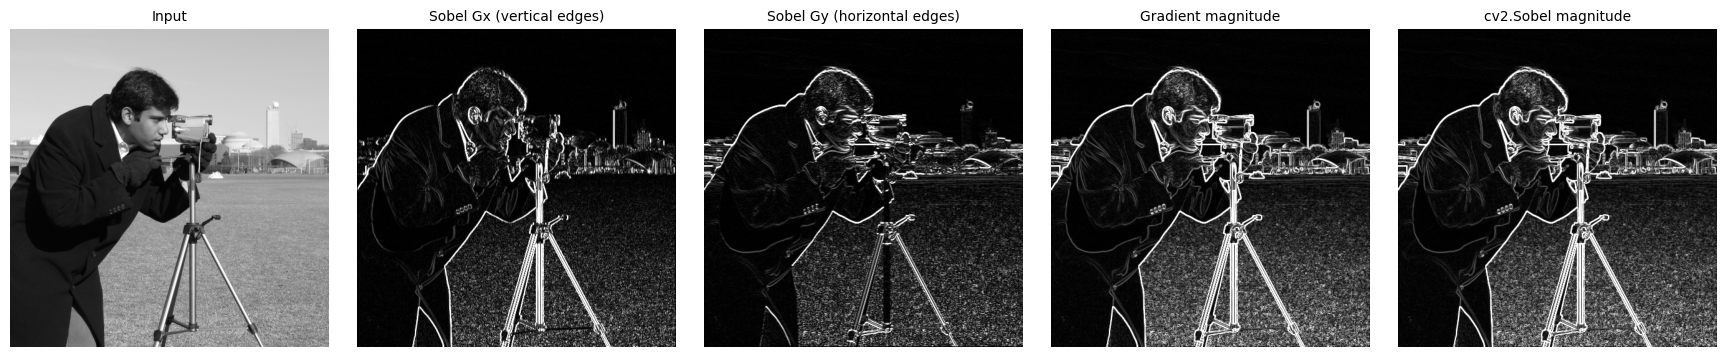

In [6]:
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64)   # horizontal gradient (Gx)
ky = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float64)   # vertical gradient (Gy)

gx = cv2.filter2D(img.astype(np.float64), -1, kx)
gy = cv2.filter2D(img.astype(np.float64), -1, ky)
sobel_mag = np.sqrt(gx ** 2 + gy ** 2)

# cross-check with OpenCV's built-in Sobel
sobel_cv = cv2.convertScaleAbs(cv2.magnitude(cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3),
                                             cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)))

show([img, to_u8(np.abs(gx)), to_u8(np.abs(gy)), to_u8(sobel_mag), sobel_cv],
     ['Input', 'Sobel Gx (vertical edges)', 'Sobel Gy (horizontal edges)',
      'Gradient magnitude', 'cv2.Sobel magnitude'],
     cols=5, size=3.5, save='04a_sobel')

### 4b. Box filter

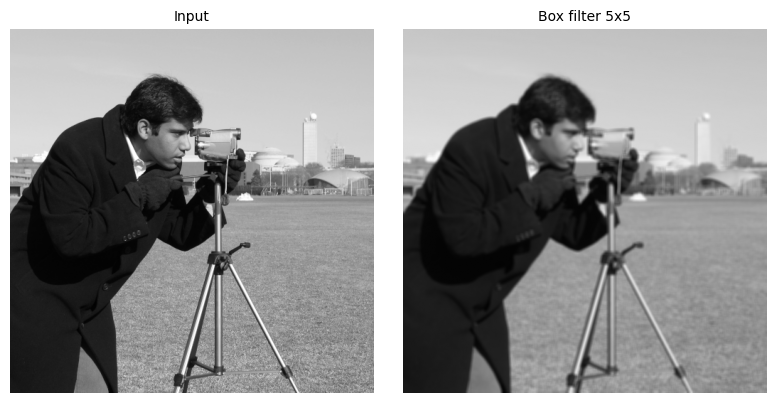

Box kernel:
 [[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]


In [7]:
box_k = np.ones((5, 5), np.float64) / 25.0
box_img = cv2.filter2D(img, -1, box_k)
show([img, box_img], ['Input', 'Box filter 5x5'], cols=2, save='04b_box')
print('Box kernel:\n', box_k)

### 4c. Weighted average filter

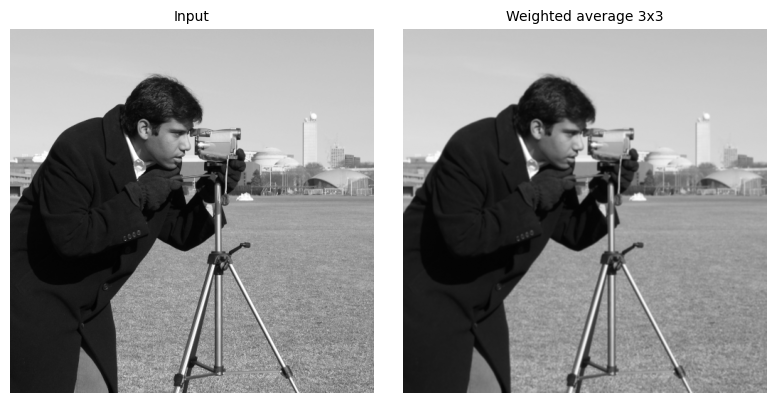

Weighted average kernel:
 [[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]


In [9]:
wavg_k = np.array([[1, 2, 1],
                   [2, 4, 2],
                   [1, 2, 1]],
                  dtype=np.float64) / 16.0
wavg_img = cv2.filter2D(img, -1, wavg_k)
show([img, wavg_img], ['Input', 'Weighted average 3x3'], cols=2, save='04c_weighted')
print('Weighted average kernel:\n', wavg_k)

### 4d. Gaussian filter mask

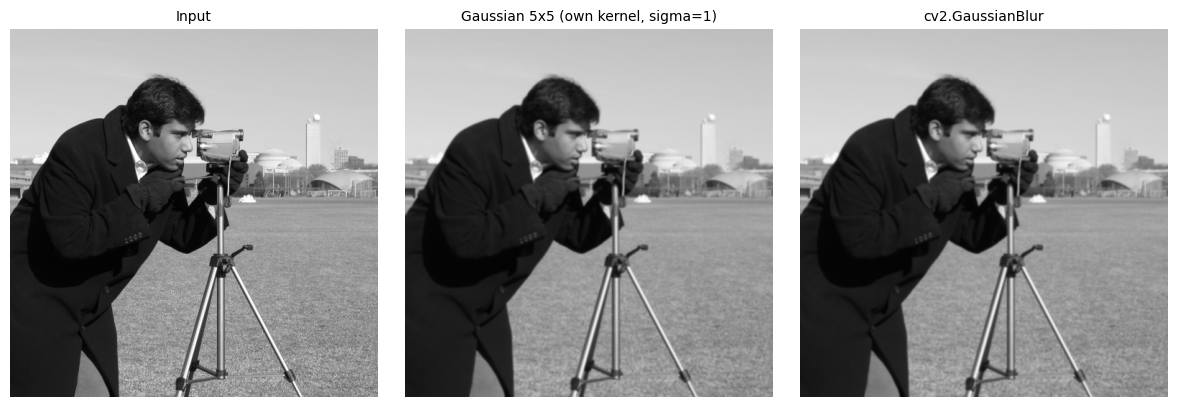

Gaussian kernel:
 [[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]


In [10]:
def gaussian_kernel(size=5, sigma=1.0):
    ax = np.arange(-(size // 2), size // 2 + 1)
    xx, yy = np.meshgrid(ax, ax)
    k = np.exp(-(xx ** 2 + yy ** 2) / (2 * sigma ** 2))
    return k / k.sum()

g_k = gaussian_kernel(5, 1.0)
g_img = cv2.filter2D(img, -1, g_k)
g_cv = cv2.GaussianBlur(img, (5, 5), 1.0)

show([img, g_img, g_cv], ['Input', 'Gaussian 5x5 (own kernel, sigma=1)', 'cv2.GaussianBlur'],
     cols=3, save='04d_gaussian')
print('Gaussian kernel:\n', np.round(g_k, 4))

### 4e. Sharpening filter

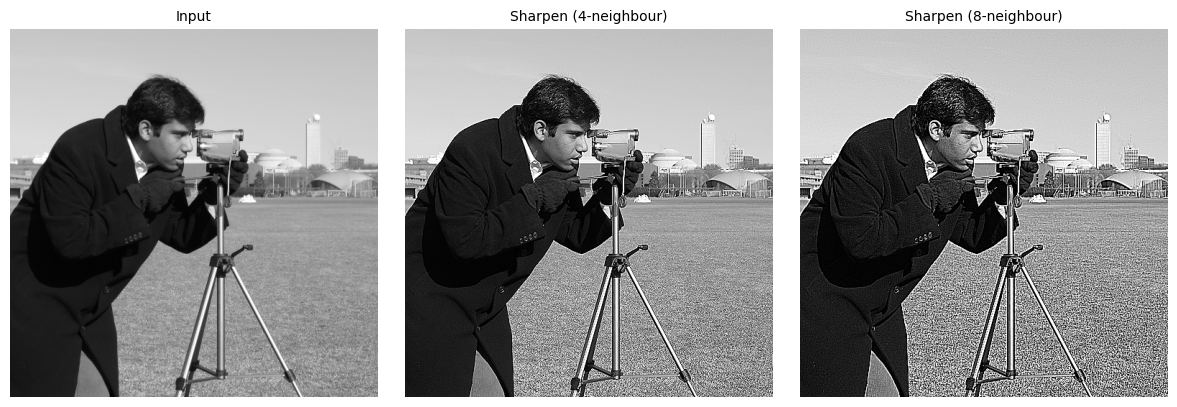

In [11]:
sharp_k = np.array([[0, -1, 0],
                    [-1, 5, -1],
                    [0, -1, 0]], dtype=np.float64)
sharp_img = to_u8(cv2.filter2D(img.astype(np.float64), -1, sharp_k))

sharp_k2 = np.array([[-1, -1, -1],
                     [-1, 9, -1],
                     [-1, -1, -1]], dtype=np.float64)
sharp_img2 = to_u8(cv2.filter2D(img.astype(np.float64), -1, sharp_k2))

show([img, sharp_img, sharp_img2],
     ['Input', 'Sharpen (4-neighbour)', 'Sharpen (8-neighbour)'],
     cols=3, save='04e_sharpen')

### 4f. Min, Max, Mean and Median filters
Salt-and-pepper noise is added so the effect of each order-statistic filter is easy to see.

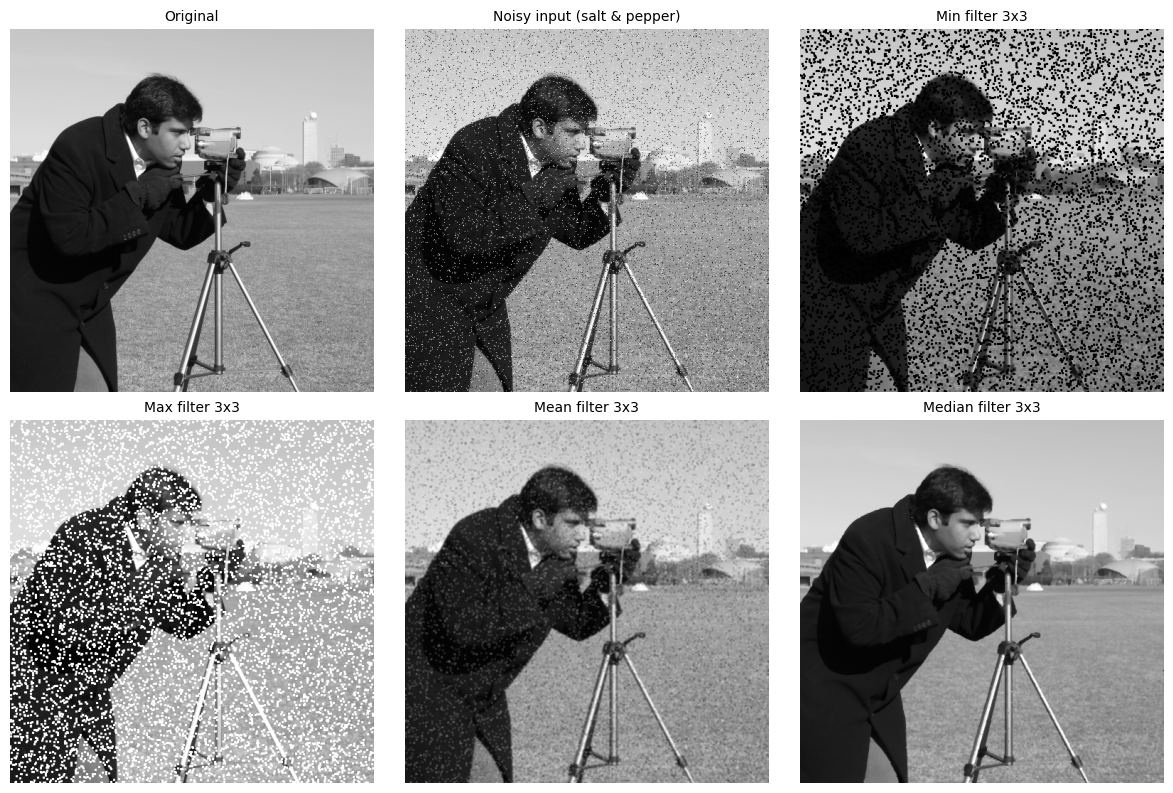

In [12]:
rng = np.random.default_rng(0)
noisy = img.copy()
r = rng.random(img.shape)
noisy[r < 0.03] = 0        # pepper
noisy[r > 0.97] = 255      # salt

min_img    = ndimage.minimum_filter(noisy, size=3)
max_img    = ndimage.maximum_filter(noisy, size=3)
mean_img   = cv2.blur(noisy, (3, 3))
median_img = cv2.medianBlur(noisy, 3)

show([img, noisy, min_img, max_img, mean_img, median_img],
     ['Original', 'Noisy input (salt & pepper)', 'Min filter 3x3', 'Max filter 3x3',
      'Mean filter 3x3', 'Median filter 3x3'],
     cols=3, save='04f_min_max_mean_median')

## Task 5: Laplacian, Enhanced Laplacian and High-boost masks

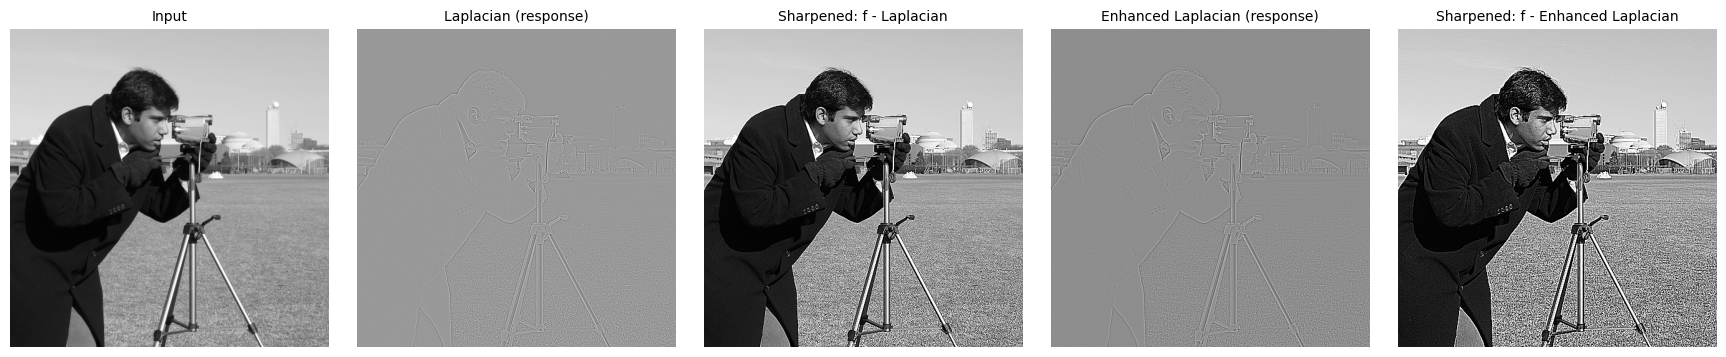

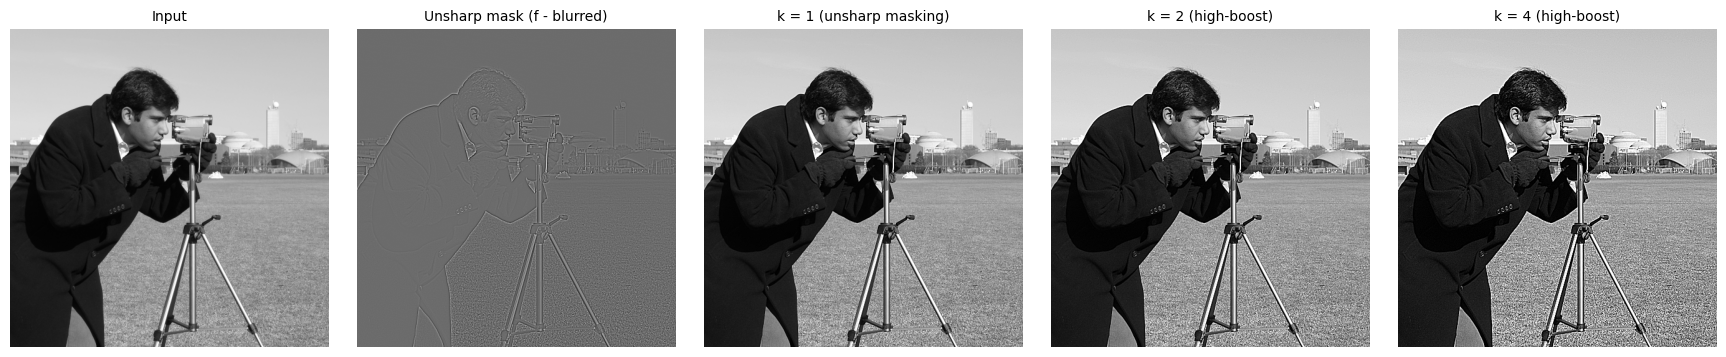

In [13]:
f = img.astype(np.float64)

# Standard Laplacian (4-neighbour, centre = -4)
lap_k = np.array([[0, 1, 0],
                  [1, -4, 1],
                  [0, 1, 0]], dtype=np.float64)

# Enhanced Laplacian (8-neighbour, centre = -8)
lap_enh_k = np.array([[1, 1, 1],
                      [1, -8, 1],
                      [1, 1, 1]], dtype=np.float64)

lap = cv2.filter2D(f, -1, lap_k)
lap_enh = cv2.filter2D(f, -1, lap_enh_k)

# Centre coefficient is negative, so sharpened = f - Laplacian
lap_sharp = to_u8(f - lap)
lap_enh_sharp = to_u8(f - lap_enh)

show([img, norm_u8(lap), lap_sharp, norm_u8(lap_enh), lap_enh_sharp],
     ['Input', 'Laplacian (response)', 'Sharpened: f - Laplacian',
      'Enhanced Laplacian (response)', 'Sharpened: f - Enhanced Laplacian'],
     cols=5, size=3.5, save='05_laplacian')

# High-boost filtering: g = f + k * (f - blurred),  k = 1 -> unsharp masking, k > 1 -> high-boost
blurred = cv2.GaussianBlur(f, (5, 5), 1.0)
unsharp_mask = f - blurred

hb1 = to_u8(f + 1 * unsharp_mask)   # unsharp masking
hb2 = to_u8(f + 2 * unsharp_mask)   # high-boost k=2
hb4 = to_u8(f + 4 * unsharp_mask)   # high-boost k=4

show([img, norm_u8(unsharp_mask), hb1, hb2, hb4],
     ['Input', 'Unsharp mask (f - blurred)', 'k = 1 (unsharp masking)',
      'k = 2 (high-boost)', 'k = 4 (high-boost)'],
     cols=5, size=3.5, save='05_high_boost')